# Лабораторная работа №2. Метод ломаных (метод Пиявского)

**Ф.И.О.:** Мурашов Никита Александрович · **Поток:** МетОпт 1.2

Поиск глобального экстремума липшицевой функции на отрезке. Код — пакет `piyavsky` (`method.py`, `validation.py`,
`plotting.py`) и `main.py`. Отчёт — `report.md`.

* gᵢ(x) = W(uᵢ) − L·|x − uᵢ| ≤ W(x), ломаная pₙ(x) = max gᵢ(x).
* u₀ = a, u₁ = b, uₙ = argmin pₙ₋₁(x) — нижняя вершина ломаной:
  u = (xᵢ + xᵢ₊₁)/2 + (W(xᵢ) − W(xᵢ₊₁))/(2L).
* Остановка: W(uₙ) − pₙ₋₁(uₙ) < eps.
* L, если не задана: 1,2 · max |ΔW/h| на сетке из 10 000 шагов (как в Excel).

In [1]:
import warnings
import matplotlib.pyplot as plt
from piyavsky import minimize, parse_number, summary
from piyavsky.plotting import plot

plt.rcParams["figure.dpi"] = 110
warnings.formatwarning = lambda message, *args, **kwargs: f"Предупреждение: {message}\n"

## Функция Растригина

На [−5,12; 5,12] 11 локальных минимумов, глобальный W(0) = 0.

Функция: 10 + x^2 - 10*cos(2*pi*x)
Глобальный минимум: x* = 0.000000, W(x*) = 0.000000
Гарантированная погрешность по значению: 6.59e-03
Константа Липшица: L = 85.5989
Итераций: 201 (вычислений W: 202)
Время: 21.7 мс, статус: eps


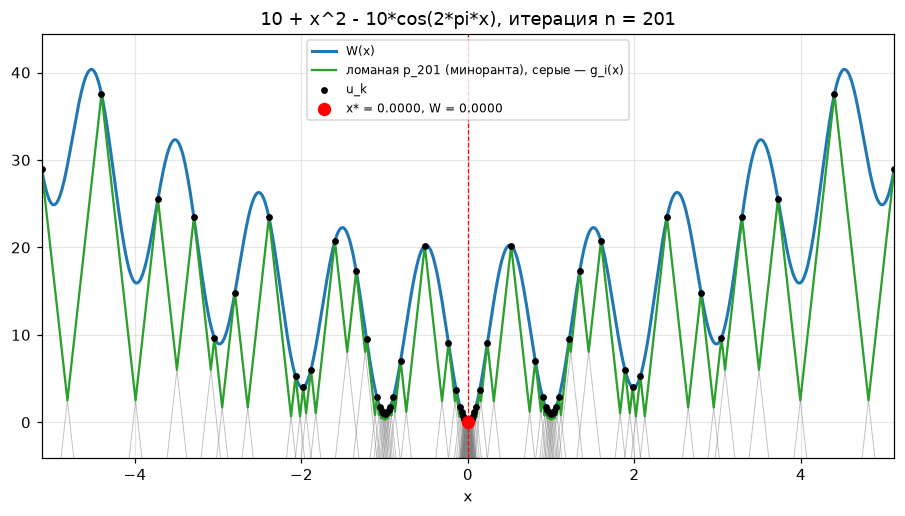

In [2]:
function = "10 + x^2 - 10*cos(2*pi*x)"
a, b = parse_number("-5,12"), parse_number("5,12")
eps = parse_number("0,01")

result = minimize(function, a, b, eps)
print(summary(result))
plot(result);

На несимметричном отрезке:

Функция: 10 + x^2 - 10*cos(2*pi*x)
Глобальный минимум: x* = 0.000015, W(x*) = 0.000000
Гарантированная погрешность по значению: 6.72e-03
Константа Липшица: L = 85.5991
Итераций: 205 (вычислений W: 206)
Время: 89.1 мс, статус: eps


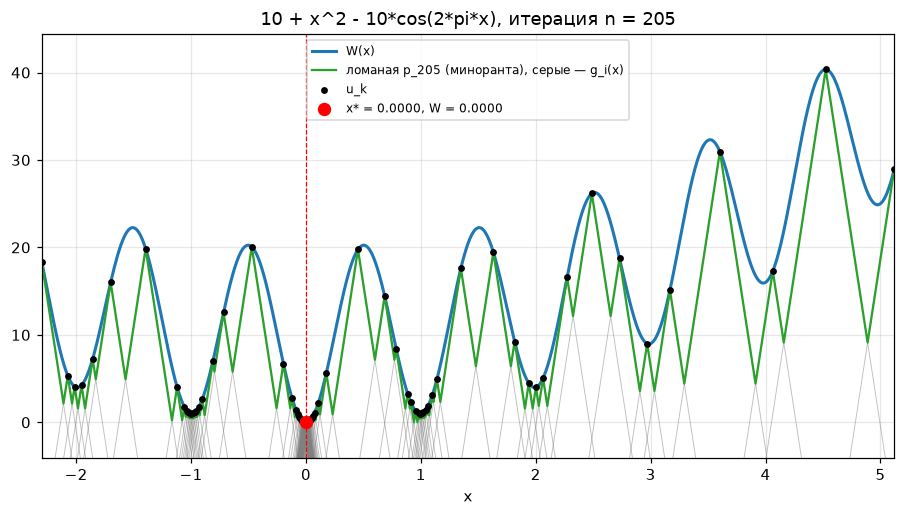

In [3]:
result = minimize(function, -2.3, 5.12, eps)
print(summary(result))
plot(result);

## Функция Экли

Глобальный минимум W(0) = 0 в точке излома.

Функция: -20*exp(-0.2*sqrt(x^2)) - exp(cos(2*pi*x)) + 20 + e
Глобальный минимум: x* = 0.000000, W(x*) = 0.000000
Гарантированная погрешность по значению: 3.57e-03
Константа Липшица: L = 15.6611
Итераций: 37 (вычислений W: 38)
Время: 14.4 мс, статус: eps


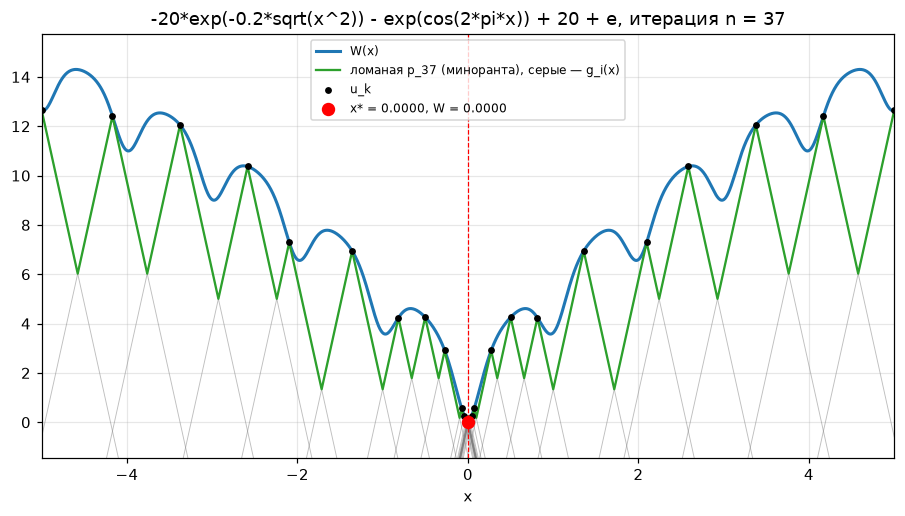

In [4]:
result = minimize("-20*exp(-0.2*sqrt(x^2)) - exp(cos(2*pi*x)) + 20 + e", -5, 5, 0.01)
print(summary(result))
plot(result);

## Пример из Excel-файла

L взята из ячейки F30. Итерации 1–4 и итоговая ломаная.

Функция: 0.5*x+0.2*cos(3.14*x)+0.2*sin(2*3.14*x)
Глобальный минимум: x* = -1.256545, W(x*) = -0.966907
Гарантированная погрешность по значению: 8.65e-03
Константа Липшица: L = 2.1543
Итераций: 28 (вычислений W: 29)
Время: 10.5 мс, статус: eps
u_2..u_6: [-0.75486  -1.488329 -0.021391 -1.751397 -1.225262]


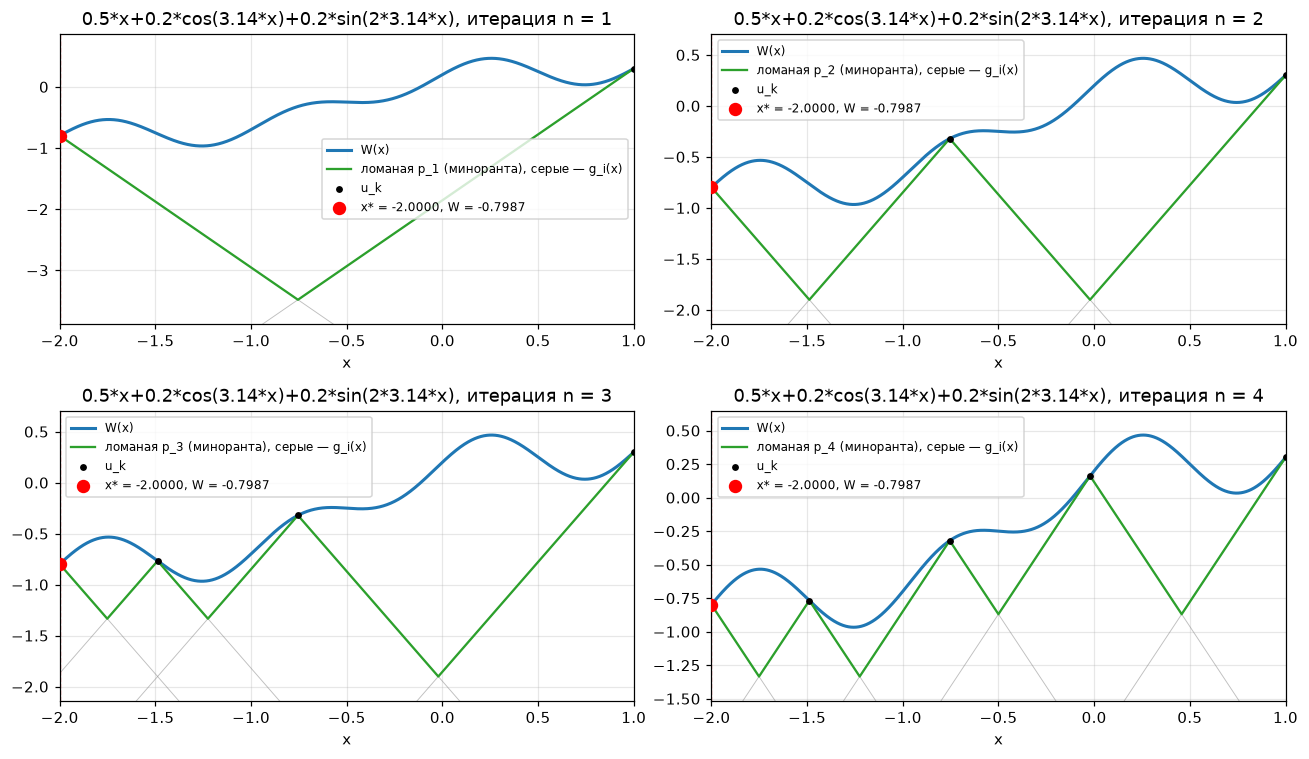

In [5]:
result = minimize("0.5*x+0.2*cos(3.14*x)+0.2*sin(2*3.14*x)", -2, 1, 0.01, L=2.1542997412292588)
print(summary(result))
print("u_2..u_6:", result.points[2:7, 0].round(6))

fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for n, ax in zip([1, 2, 3, 4], axes.flat):
    plot(result, n=n, ax=ax)
fig.tight_layout()

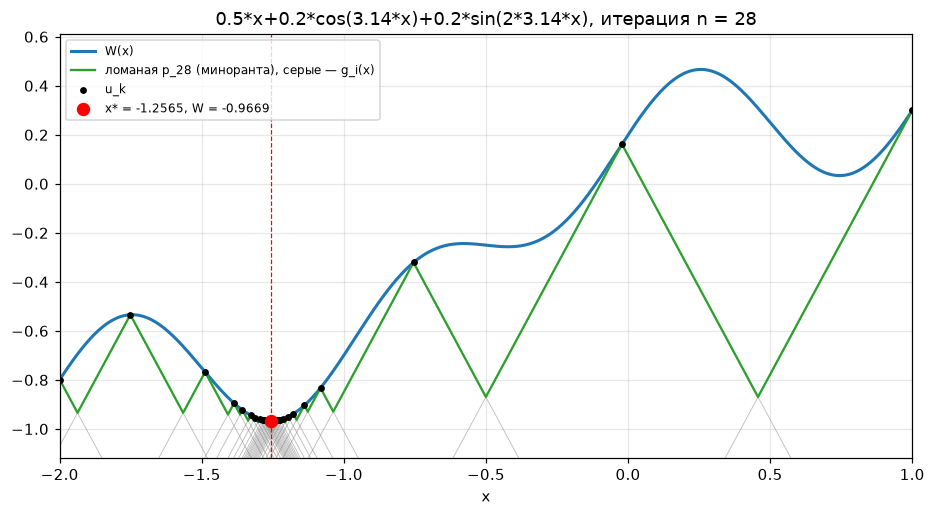

In [6]:
plot(result);

## Пример из задания: минимум и максимум

Функция: x + sin(3.14159*x)
Глобальный минимум: x* = -0.603622, W(x*) = -1.551101
Гарантированная погрешность по значению: 8.55e-03
Константа Липшица: L = 4.96991
Итераций: 53 (вычислений W: 54)
Время: 10.7 мс, статус: eps

Функция: x + sin(3.14159*x)
Глобальный максимум: x* = 2.500000, W(x*) = 3.500000
Гарантированная погрешность по значению: 4.29e-03
Константа Липшица: L = 4.96991
Итераций: 15 (вычислений W: 16)
Время: 2.0 мс, статус: eps



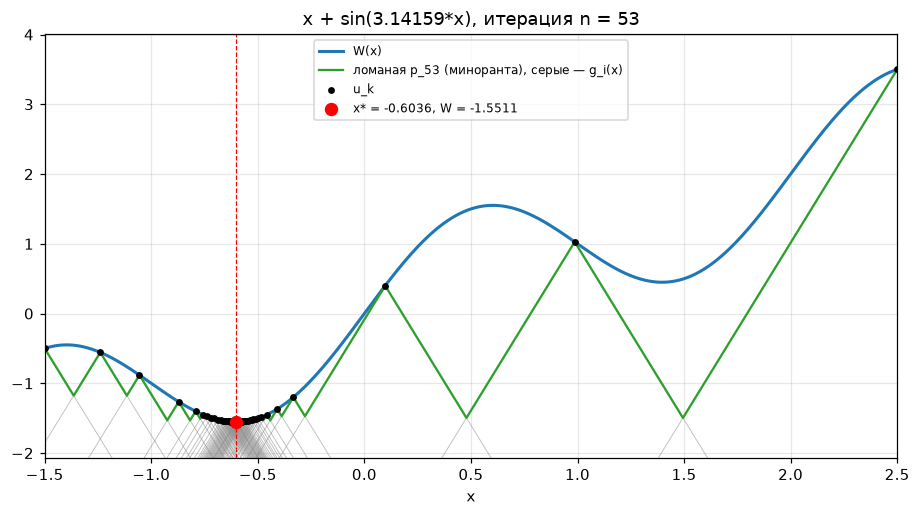

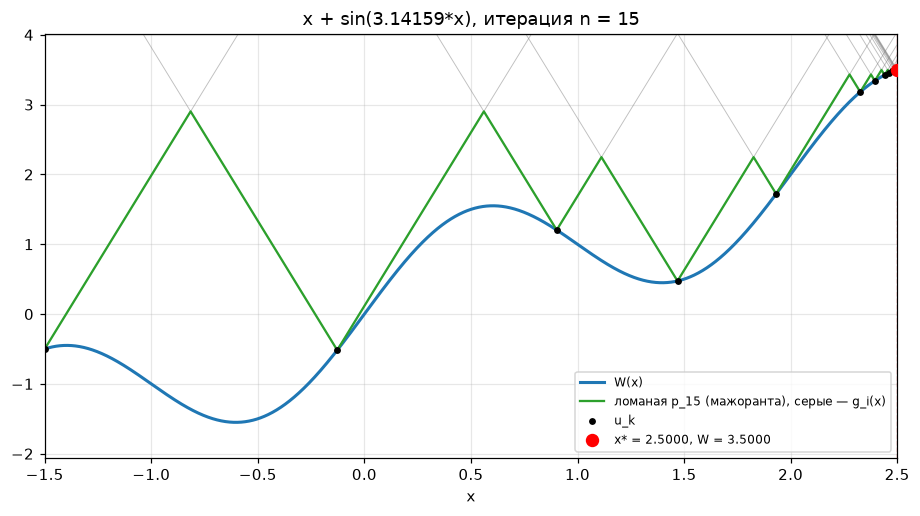

In [7]:
for mode in ["min", "max"]:
    result = minimize("x + sin(3.14159*x)", -1.5, 2.5, 0.01, mode=mode)
    print(summary(result), end="\n\n")
    plot(result)

## Некорректный ввод

In [8]:
cases = [
    ("2x", 0, 1, 0.01, {}),
    ("foo(x)", 0, 1, 0.01, {}),
    ("__import__('os')", 0, 1, 0.01, {}),
    ("log(x)", -1, 1, 0.01, {}),
    ("x^2", 1, -1, 0.01, {}),
    ("x^2", -1, 1, 0, {}),
    ("10 + x^2 - 10*cos(2*pi*x)", -5, 5, 0.01, {"L": 1}),
]
for function, a, b, eps, extra in cases:
    try:
        minimize(function, a, b, eps, **extra)
    except ValueError as error:
        print(f"{function!r:32} -> {error}")

'2x'                             -> не удалось разобрать «2x» (умножение пишется явно: 2*x)
'foo(x)'                         -> неизвестная функция «foo», доступны: sin, cos, tan, asin, acos, atan, sinh, cosh, tanh, exp, log, ln, log10, sqrt, abs, min, max
"__import__('os')"               -> неизвестная функция «__import__», доступны: sin, cos, tan, asin, acos, atan, sinh, cosh, tanh, exp, log, ln, log10, sqrt, abs, min, max
'log(x)'                         -> W(-1) = nan: функция не определена или не конечна на отрезке, значит она не липшицева
'x^2'                            -> нужно a < b, получено a = 1, b = -1
'x^2'                            -> нужно eps > 0, получено 0
'10 + x^2 - 10*cos(2*pi*x)'      -> между x = -5 и x = 0 наклон 5 больше L = 1: условие Липшица нарушено. Увеличьте L или не задавайте её.


Лимит итераций:

In [9]:
result = minimize("10 + x^2 - 10*cos(2*pi*x)", -5.12, 5.12, 1e-9, max_iter=20)
print(summary(result))

Функция: 10 + x^2 - 10*cos(2*pi*x)
Глобальный минимум: x* = 0.000000, W(x*) = 0.000000
Гарантированная погрешность по значению: 1.21e+01
Константа Липшица: L = 85.5989
Итераций: 20 (вычислений W: 21)
Время: 22.8 мс, статус: max_iter


Предупреждение: точность eps не достигнута (max_iter), результат может быть хуже на W(x*) - min p
